<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/13-evaluating-classifiers/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 13: Evaluating Classifiers

A classifier that is "95% accurate" might be excellent, useless or dangerous. It depends on how common each class is, which mistakes it makes, what those mistakes cost, and whether its probabilities can be believed. This module is about answering those questions properly.

It's one of the most practical modules in the course. Choosing the wrong metric is one of the most common ways real machine learning projects go wrong, and it happens to experienced people too. By the end you'll be able to look at any classifier and say what it's good for, where to set its threshold, and how sure you can be.

**Contents**

1. Why accuracy isn't enough
2. The confusion matrix
3. Precision, recall and friends
4. Scores and thresholds
5. ROC curves and AUC
6. Precision-recall curves
7. Choosing a threshold with costs
8. Calibration: can you trust the probabilities?
9. Class imbalance
10. More than two classes
11. How sure are you? Comparing classifiers
12. A checklist for evaluating classifiers

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. Why accuracy isn't enough

Imagine a screening test for a disease that 1 in 100 people have. Here's a "test" that needs no data and no training: it says **healthy** to everyone.

In [3]:
rng = np.random.default_rng(0)
has_disease = rng.random(10_000) < 0.01          # about 1% of 10,000 people
always_healthy = np.zeros(10_000, dtype=bool)    # the "test": nobody has it

accuracy = np.mean(always_healthy == has_disease)
print(f"people with the disease: {has_disease.sum()}")
print(f"accuracy of saying 'healthy' to everyone: {accuracy:.1%}")
print(f"sick people it finds: {np.sum(always_healthy & has_disease)}")

people with the disease: 89
accuracy of saying 'healthy' to everyone: 99.1%
sick people it finds: 0


Around 99% accurate, and it never finds a single sick person. Accuracy counts every correct answer the same, so when one class is rare, a model can score highly by ignoring it.

Two questions decide how a classifier should be judged, and accuracy answers neither:

1. **How common is each class?** This is the **base rate** (or prevalence). Every number in this module only makes sense next to it.
2. **What does each kind of mistake cost?** Missing a disease and raising a false alarm are not equally bad.

The rest of the module builds the tools that answer these questions. The main example is a real medical dataset that ships with scikit-learn: **569 breast tumours**, each described by 30 measurements of cell nuclei taken from a scan of a fine needle biopsy, and labelled **malignant** (cancer) or **benign**.

In [4]:
cancer = load_breast_cancer(as_frame=True)
X_bc = cancer.data
y_bc = (cancer.target == 0).astype(int)     # in this dataset 0 means malignant; we make malignant = 1
print(X_bc.shape)
print(f"malignant: {y_bc.sum()} of {len(y_bc)} ({y_bc.mean():.0%})")

(569, 30)
malignant: 212 of 569 (37%)


By convention, the class you're trying to detect is called **positive** (here, malignant) and the other **negative**. "Positive" doesn't mean good; it means "the thing we're looking for is present".

Every evaluation must use predictions for data the model didn't train on. `cross_val_predict` (Module 11) gives each tumour a predicted probability from a model trained on the other folds:

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
model_bc = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
p_bc = cross_val_predict(model_bc, X_bc, y_bc, cv=cv, method="predict_proba")[:, 1]
pred_bc = (p_bc >= 0.5).astype(int)
print(f"accuracy: {np.mean(pred_bc == y_bc):.1%}")

accuracy: 97.5%


High accuracy, and this time the classes aren't very imbalanced, so it means something. But it still hides the question that matters most for a cancer test: **of the mistakes, how many were missed cancers?**

## 2. The confusion matrix

Every prediction of a binary classifier falls into one of four boxes:

| | predicted negative | predicted positive |
|---|---|---|
| **actually negative** | **true negative** (TN) | **false positive** (FP): a false alarm |
| **actually positive** | **false negative** (FN): a miss | **true positive** (TP) |

The table of counts is called the **confusion matrix**, and it's the starting point for every classification metric. Here it is, counted by hand and with scikit-learn:

In [6]:
from sklearn.metrics import confusion_matrix

tp = np.sum((pred_bc == 1) & (y_bc == 1))
fp = np.sum((pred_bc == 1) & (y_bc == 0))
fn = np.sum((pred_bc == 0) & (y_bc == 1))
tn = np.sum((pred_bc == 0) & (y_bc == 0))
print(f"TP {tp}   FP {fp}   FN {fn}   TN {tn}")
print(confusion_matrix(y_bc, pred_bc))      # rows: actual 0, 1; columns: predicted 0, 1

TP 199   FP 1   FN 13   TN 356
[[356   1]
 [ 13 199]]


scikit-learn puts the **actual** classes in rows and the **predicted** classes in columns, in sorted order (0 then 1), so the layout is `[[TN, FP], [FN, TP]]`. Other tools and textbooks sometimes flip it. Always check which way round a confusion matrix is before reading it.

A picture makes the counts easier to read:

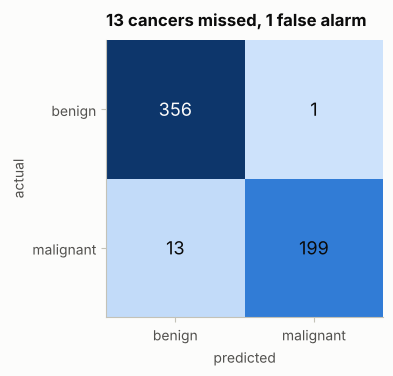

In [7]:
def plural(n, word):
    return f"{n} {word}" + ("" if n == 1 else "s")


def plot_confusion(cm, labels, ax, title):
    ax.imshow(cm, cmap=SEQUENTIAL, vmin=0)
    ax.grid(False)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            colour = SURFACE if cm[i, j] > cm.max() * 0.6 else INK
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=13, color=colour)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(4, 3.6))
plot_confusion(confusion_matrix(y_bc, pred_bc), ["benign", "malignant"], ax,
               f"{plural(fn, 'cancer')} missed, {plural(fp, 'false alarm')}")
plt.show()

The two kinds of mistake have very different consequences. A **false positive** means a healthy patient gets a follow-up test and some worry. A **false negative** means a cancer goes undetected. A doctor would gladly accept many more false alarms to miss fewer cancers. Accuracy treats them as equal.

## 3. Precision, recall and friends

Each metric below is a ratio of boxes in the confusion matrix, and each answers a different question:

| metric | formula | the question it answers |
|---|---|---|
| **recall** (sensitivity, true positive rate) | TP / (TP + FN) | Of the real positives, what fraction did we find? |
| **precision** (positive predictive value) | TP / (TP + FP) | When the model says positive, how often is it right? |
| **specificity** (true negative rate) | TN / (TN + FP) | Of the real negatives, what fraction did we correctly clear? |
| **false positive rate** | FP / (FP + TN) = 1 - specificity | Of the real negatives, what fraction raised a false alarm? |
| **accuracy** | (TP + TN) / all | What fraction of all predictions were right? |

Recall and precision pull against each other. A model that flags **everything** has perfect recall and terrible precision; a model that flags only the one case it's surest about can have perfect precision and terrible recall. Which matters more depends on the problem:

- **Recall matters most** when misses are costly: cancer screening, fraud, safety faults.
- **Precision matters most** when acting on a positive is costly or annoying: a spam filter (a real email in the spam folder is bad), recommending something to a customer, flagging a person for investigation.

In [8]:
recall = tp / (tp + fn)
precision = tp / (tp + fp)
specificity = tn / (tn + fp)
print(f"recall      {recall:.3f}   found {tp} of {tp + fn} cancers")
print(f"precision   {precision:.3f}   {tp} of {tp + fp} 'malignant' predictions were right")
print(f"specificity {specificity:.3f}   cleared {tn} of {tn + fp} benign tumours")

recall      0.939   found 199 of 212 cancers
precision   0.995   199 of 200 'malignant' predictions were right
specificity 0.997   cleared 356 of 357 benign tumours


### Combining precision and recall

Sometimes you need a single number. The **F1 score** is the **harmonic mean** of precision and recall:

$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

The harmonic mean is pulled towards the smaller of the two, so a model can't get a good F1 by being excellent at one and terrible at the other: precision 1.0 with recall 0.1 gives F1 = 0.18, not the 0.55 an ordinary average would give.

The **F-beta score** generalises it: `β > 1` weights recall more (F2 is common in screening), `β < 1` weights precision more.

$$F_\beta = \frac{(1 + \beta^2) \cdot \text{precision} \cdot \text{recall}}{\beta^2 \cdot \text{precision} + \text{recall}}$$

Two more single numbers that handle imbalance well:

- **Balanced accuracy**: the average of recall and specificity, so each class counts equally however rare it is. A model that ignores one class scores 0.5.
- **Matthews correlation coefficient** (MCC): the correlation between the predicted and actual labels, from -1 (always wrong) through 0 (no better than chance) to 1 (perfect). It uses all four boxes and is only high when the model does well on both classes.

scikit-learn has all of them, and `classification_report` prints the per-class numbers in one go:

In [9]:
from sklearn.metrics import (balanced_accuracy_score, classification_report, f1_score, fbeta_score,
                             matthews_corrcoef, precision_score, recall_score)

print(f"F1 by hand {2 * precision * recall / (precision + recall):.3f}   scikit-learn {f1_score(y_bc, pred_bc):.3f}")
print(f"F2 {fbeta_score(y_bc, pred_bc, beta=2):.3f}   balanced accuracy {balanced_accuracy_score(y_bc, pred_bc):.3f}   MCC {matthews_corrcoef(y_bc, pred_bc):.3f}")
print()
print(classification_report(y_bc, pred_bc, target_names=["benign", "malignant"], digits=3))

F1 by hand 0.966   scikit-learn 0.966


F2 0.949   balanced accuracy 0.968   MCC 0.948



              precision    recall  f1-score   support

      benign      0.965     0.997     0.981       357
   malignant      0.995     0.939     0.966       212

    accuracy                          0.975       569
   macro avg      0.980     0.968     0.973       569
weighted avg      0.976     0.975     0.975       569



How to read the report: each row treats that class as the positive one. The `malignant` row's recall is the recall from before; the `benign` row's recall is the specificity. **Support** is the number of real examples of each class. The averages at the bottom are explained in section 10.

### The accuracy paradox, measured

Back to the rare disease. We'll make the data ourselves, so we know exactly what's in it: 20,000 cases with five measurements each, about 1% of them positive, and positives tend to have higher measurements. Half the cases train a logistic regression; the other half are the test set. Compare three classifiers: the "always negative" one, and the logistic regression with two different thresholds (section 4 explains thresholds properly):

In [10]:
from sklearn.model_selection import train_test_split


def make_screening_data(n, prevalence, separation, seed):
    """Five measurements per case. Positives are shifted upwards, so they tend to score higher."""
    rng = np.random.default_rng(seed)
    y = (rng.random(n) < prevalence).astype(int)
    X = rng.normal(size=(n, 5))
    X[y == 1] += separation / np.sqrt(5)
    return X, y


X_r, y_r = make_screening_data(20_000, prevalence=0.01, separation=2.3, seed=1)
X_r_train, X_r_test, y_r_train, y_r_test = train_test_split(X_r, y_r, test_size=0.5, stratify=y_r, random_state=0)
rare_model = LogisticRegression(max_iter=1000).fit(X_r_train, y_r_train)
p_rare = rare_model.predict_proba(X_r_test)[:, 1]

rows = {}
for name, pred in [("always negative", np.zeros_like(y_r_test)),
                   ("logistic, threshold 0.5", (p_rare >= 0.5).astype(int)),
                   ("logistic, threshold 0.1", (p_rare >= 0.1).astype(int))]:
    rows[name] = {
        "accuracy": np.mean(pred == y_r_test),
        "balanced acc.": balanced_accuracy_score(y_r_test, pred),
        "recall": recall_score(y_r_test, pred),
        "precision": precision_score(y_r_test, pred, zero_division=0),
        "F1": f1_score(y_r_test, pred),
        "MCC": matthews_corrcoef(y_r_test, pred),
    }
print(f"positives in the test set: {y_r_test.sum()} of {len(y_r_test)}")
pd.DataFrame(rows).T.round(3)

positives in the test set: 92 of 10000


,accuracy,balanced acc.,recall,precision,F1,MCC
always negative,0.991,0.500,0.000,0.000,0.000,0.000
"logistic, threshold 0.5",0.993,0.630,0.261,0.889,0.403,0.479
"logistic, threshold 0.1",0.985,0.777,0.565,0.313,0.403,0.414


All three have almost the same accuracy, so accuracy can't tell them apart. The other metrics can: the "always negative" classifier gets zero recall, balanced accuracy 0.5 and MCC 0. The logistic regression with the default threshold of 0.5 finds only a minority of the positives; lowering the threshold to 0.1 finds many more, at some cost in precision. That trade-off, controlled by the threshold, is the subject of the next section.

`zero_division=0` tells scikit-learn what to report when precision is undefined: the "always negative" model makes no positive predictions, so TP + FP = 0 and the formula would divide by zero.

## 4. Scores and thresholds

Most classifiers don't output a label. They output a **score**: a probability from logistic regression, a vote share from a forest, a distance from an SVM's boundary. The label comes from a **threshold** that you choose: predict positive if the score is above it.

`model.predict` uses a threshold of 0.5 for probabilities. That's a default, not a law, and it's rarely the right choice. Moving the threshold trades one kind of mistake for the other:

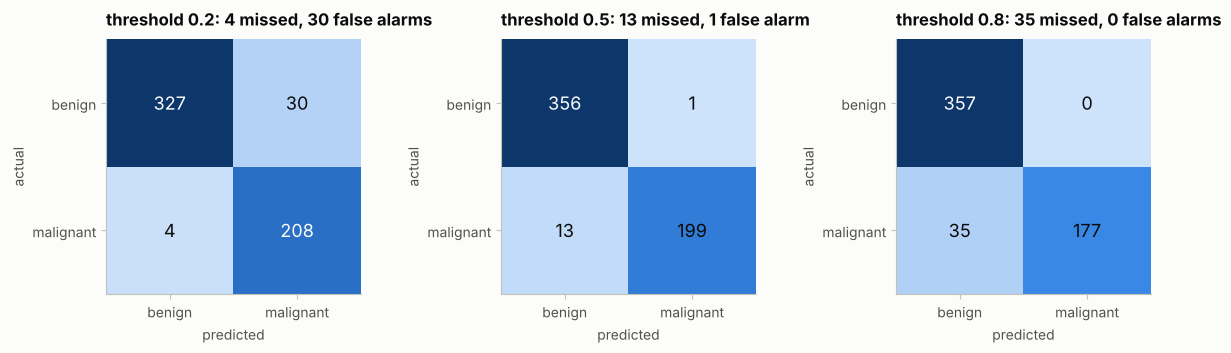

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, threshold in zip(axes, [0.2, 0.5, 0.8]):
    pred = (p_bc >= threshold).astype(int)
    cm = confusion_matrix(y_bc, pred)
    plot_confusion(cm, ["benign", "malignant"], ax, f"threshold {threshold}: {cm[1, 0]} missed, {plural(cm[0, 1], 'false alarm')}")
fig.tight_layout()
plt.show()

A low threshold calls more tumours malignant: fewer missed cancers, more false alarms. A high threshold does the opposite. None of the three is "the accuracy of the model"; they're three different **operating points** of the same model.

Plotting precision and recall for every threshold shows the whole trade-off:

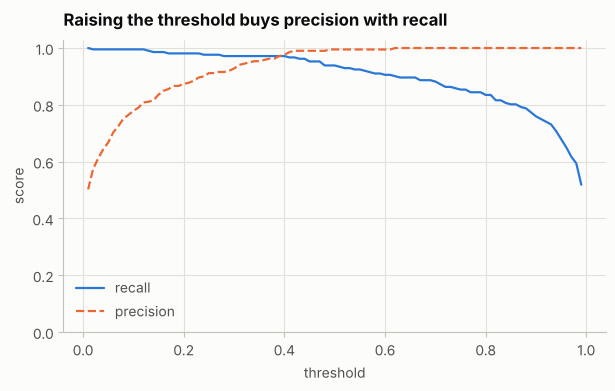

In [12]:
thresholds = np.linspace(0.01, 0.99, 99)
precisions = [precision_score(y_bc, p_bc >= t, zero_division=1) for t in thresholds]
recalls = [recall_score(y_bc, p_bc >= t) for t in thresholds]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thresholds, recalls, color=PALETTE[0], label="recall")
ax.plot(thresholds, precisions, color=PALETTE[1], linestyle="--", label="precision")
ax.set_xlabel("threshold")
ax.set_ylabel("score")
ax.set_ylim(0, 1.03)
ax.legend(loc="lower left")
ax.set_title("Raising the threshold buys precision with recall")
plt.show()

As the threshold rises, recall (solid line) falls and precision (dashed) rises. The threshold is a **business or clinical decision**, not a modelling one. The model's job is to produce good scores; the threshold turns them into actions, and section 7 shows how to choose it from what mistakes cost.

To judge the scores themselves, independent of any threshold, we need a summary that covers all thresholds at once. That's what the next two sections provide.

## 5. ROC curves and AUC

The **ROC curve** (receiver operating characteristic, a name from radar engineering in the Second World War) plots the **true positive rate** (recall) against the **false positive rate** for every possible threshold.

It's easy to compute by hand. Sort the examples from highest score to lowest, then lower the threshold one example at a time: each positive you pass moves the curve **up**, each negative moves it **right**.

In [13]:
def roc_by_hand(y, scores):
    order = np.argsort(-scores)
    y_sorted = np.asarray(y)[order]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y_sorted.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()])
    return fpr, tpr


from sklearn.metrics import roc_auc_score, roc_curve

fpr_h, tpr_h = roc_by_hand(y_bc, p_bc)
fpr_s, tpr_s, _ = roc_curve(y_bc, p_bc)
auc_bc = roc_auc_score(y_bc, p_bc)
area_by_hand = np.sum(np.diff(fpr_h) * (tpr_h[1:] + tpr_h[:-1]) / 2)     # trapezoids under the curve
print(f"area under the hand-made curve {area_by_hand:.4f}   scikit-learn AUC {auc_bc:.4f}")

area under the hand-made curve 0.9952   scikit-learn AUC 0.9952


(This simple version assumes no two examples have the same score. `roc_curve` handles ties properly, and also drops points that lie on a straight line, so it returns fewer points.)

The **AUC** is the area under the ROC curve. Here's the curve, with two reference models for comparison:

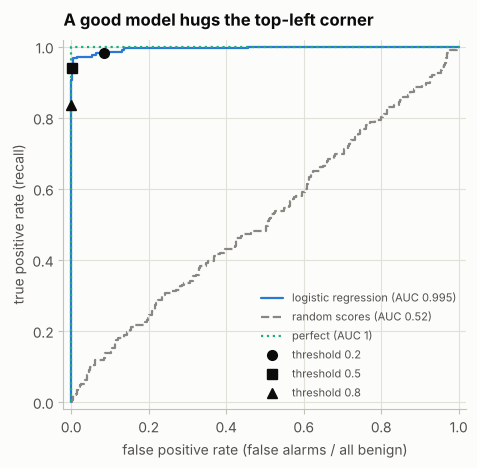

In [14]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(5.2, 4.8))
ax.plot(fpr_s, tpr_s, color=PALETTE[0], label=f"logistic regression (AUC {auc_bc:.3f})")
random_scores = rng.random(len(y_bc))
fpr_r, tpr_r, _ = roc_curve(y_bc, random_scores)
ax.plot(fpr_r, tpr_r, color=MUTED, linestyle="--", label=f"random scores (AUC {roc_auc_score(y_bc, random_scores):.2f})")
ax.plot([0, 0, 1], [0, 1, 1], color=PALETTE[2], linestyle=":", label="perfect (AUC 1)")
for threshold, marker in [(0.2, "o"), (0.5, "s"), (0.8, "^")]:
    pred = p_bc >= threshold
    ax.plot(np.mean(pred[y_bc == 0]), np.mean(pred[y_bc == 1]), marker=marker, color=INK, linestyle="none",
            markersize=7, label=f"threshold {threshold}")
ax.set_xlabel("false positive rate (false alarms / all benign)")
ax.set_ylabel("true positive rate (recall)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("A good model hugs the top-left corner")
plt.show()

How to read it:

- Every point on the curve is one threshold. The three markers are the thresholds from section 4; lowering the threshold moves you up and to the right.
- A model that ranks perfectly goes straight up to the top-left corner (all positives found before any false alarm), then across: AUC 1.
- Random scores give the diagonal: AUC 0.5. Below the diagonal means worse than random (usually a sign of a flipped label).

### What AUC means

AUC has a neat interpretation: it's the **probability that a randomly chosen positive gets a higher score than a randomly chosen negative**. It measures **ranking**: how well the scores put positives ahead of negatives. We can check this by comparing every malignant tumour with every benign one:

In [15]:
pos = p_bc[y_bc == 1]
neg = p_bc[y_bc == 0]
higher = (pos[:, None] > neg[None, :]).mean()        # every positive-negative pair (broadcasting)
ties = (pos[:, None] == neg[None, :]).mean()
print(f"pairs compared: {len(pos) * len(neg):,}")
print(f"fraction where the positive scores higher (ties count half): {higher + ties / 2:.4f}")
print(f"roc_auc_score:                                               {auc_bc:.4f}")

pairs compared: 75,684
fraction where the positive scores higher (ties count half): 0.9952
roc_auc_score:                                               0.9952


Exactly the same number. (This is also a classical statistic, the **Mann-Whitney U** statistic divided by the number of pairs.)

What this means in practice:

- **AUC ignores the threshold.** It tells you how good the scores are, not how good any particular set of decisions is.
- **AUC ignores calibration.** Squaring every score, or dividing them all by 10, changes no rankings, so the AUC stays the same even though the "probabilities" are now wrong. Section 8 deals with that.
- **AUC weighs all thresholds**, including ones you'd never use. If you'll only ever act on the top 5% of scores, a model's behaviour at the bottom is irrelevant, but it still counts in the AUC.

## 6. Precision-recall curves

The ROC curve has a blind spot. Its x-axis, the false positive rate, divides by the number of **negatives**. When negatives vastly outnumber positives, even a large number of false alarms is a small rate, so the ROC curve can look excellent while most of the model's positive predictions are wrong.

The **precision-recall curve** plots precision against recall for every threshold. Precision divides by the number of **predicted positives**, so it shows directly how many of your alerts are real. Its summary is **average precision** (AP), roughly the area under the curve.

The cleanest way to see the difference is an experiment where only the base rate changes. Suppose a model's scores for positives and negatives always come from the same two distributions (positives tend to score higher), and we change only how many negatives there are:

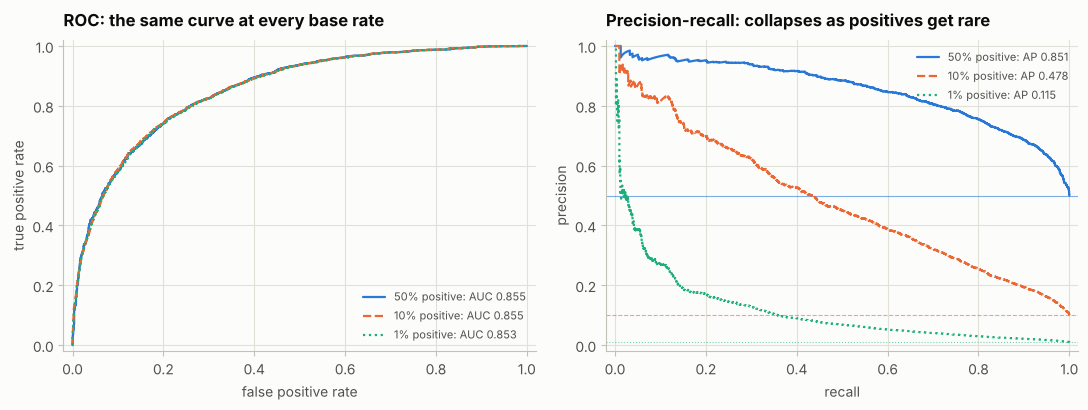

In [16]:
from sklearn.metrics import average_precision_score, precision_recall_curve

rng = np.random.default_rng(1)
n_pos = 2000
positive_scores = rng.normal(1.5, 1, n_pos)        # the same positives every time
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for (prevalence, colour, style) in [(0.5, PALETTE[0], "-"), (0.1, PALETTE[1], "--"), (0.01, PALETTE[2], ":")]:
    n_neg = int(n_pos * (1 - prevalence) / prevalence)
    scores = np.concatenate([positive_scores, rng.normal(0, 1, n_neg)])
    labels = np.concatenate([np.ones(n_pos), np.zeros(n_neg)])
    fpr, tpr, _ = roc_curve(labels, scores)
    prec, rec, _ = precision_recall_curve(labels, scores)
    axes[0].plot(fpr, tpr, color=colour, linestyle=style, label=f"{prevalence:.0%} positive: AUC {roc_auc_score(labels, scores):.3f}")
    axes[1].plot(rec, prec, color=colour, linestyle=style, label=f"{prevalence:.0%} positive: AP {average_precision_score(labels, scores):.3f}")
    axes[1].axhline(prevalence, color=colour, linestyle=style, linewidth=0.8, alpha=0.6)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC: the same curve at every base rate")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall: collapses as positives get rare")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
fig.tight_layout()
plt.show()

The model is identical in all three cases: positives score the same way, negatives score the same way. The ROC curves lie on top of each other with almost the same AUC (the small differences are sampling noise), because the true and false positive **rates** don't depend on how many of each class there are.

The precision-recall curves tell a different story. With 1% positives, finding half of the positives means also flagging many times as many negatives, so precision is low. The thin horizontal lines show each base rate, which is the precision of random guessing: **the baseline for AP is the base rate**, not 0.5.

Which to use?

- **ROC and AUC** answer "how well does the model separate the classes?" They are comparable across datasets with different base rates, which is useful for comparing models in general.
- **Precision-recall and AP** answer "if I act on the model's alerts, how many will be real?" When positives are rare and the cost is in acting on alerts (investigating fraud, calling customers, reviewing flagged content), this is usually the more honest view.

Report both when in doubt, and always say what the base rate is.

In [17]:
prec_bc, rec_bc, _ = precision_recall_curve(y_bc, p_bc)
print(f"breast cancer: AUC {auc_bc:.3f}, average precision {average_precision_score(y_bc, p_bc):.3f}, base rate {y_bc.mean():.3f}")
print(f"rare disease:  AUC {roc_auc_score(y_r_test, p_rare):.3f}, average precision {average_precision_score(y_r_test, p_rare):.3f}, base rate {y_r_test.mean():.3f}")

breast cancer: AUC 0.995, average precision 0.994, base rate 0.373
rare disease:  AUC 0.959, average precision 0.482, base rate 0.009


On the breast cancer data (37% positive) both numbers are high. On the rare disease data, the AUC still looks strong, but the average precision is far lower: this model's alerts would often be false alarms, and only the precision-recall view shows it.

## 7. Choosing a threshold with costs

If you can put a cost on each kind of mistake, the best threshold follows from a short calculation. Suppose the model says a case has probability `p` of being positive, and:

- a **false positive** costs `C_FP` (an unnecessary follow-up test, say)
- a **false negative** costs `C_FN` (a missed cancer)

If you predict **positive**, you pay `C_FP` when the case is actually negative, which happens with probability `1 - p`. If you predict **negative**, you pay `C_FN` when it's actually positive, with probability `p`. Predict positive when that's the cheaper choice:

$$(1 - p) \cdot C_{FP} < p \cdot C_{FN} \quad\Longleftrightarrow\quad p > \frac{C_{FP}}{C_{FP} + C_{FN}}$$

When the two mistakes cost the same, the threshold is 0.5. When a miss costs 10 times as much as a false alarm, it's 1/11, about 0.09: act even when the model thinks cancer is fairly unlikely. (Correct predictions can have costs or benefits too; the same reasoning works with all four boxes, and you'll do that in the mini project.)

Let's check it against the data. Say a missed cancer is 10 times as costly as a false alarm. (Real costs in medicine are much harder to put numbers on; the point here is the method.)

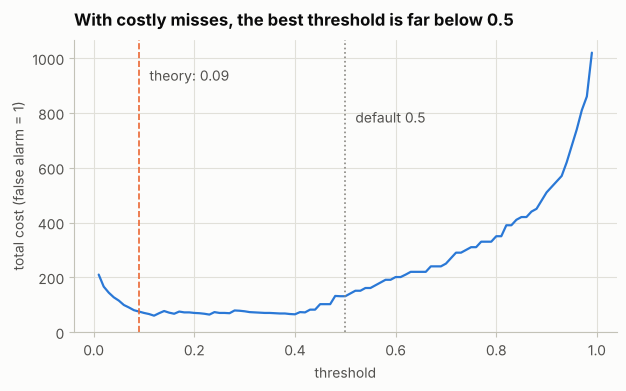

threshold 0.09: total cost 75
threshold 0.12: total cost 60
threshold 0.50: total cost 131


In [18]:
cost_fp, cost_fn = 1, 10
thresholds = np.linspace(0.01, 0.99, 99)
total_cost = [cost_fp * np.sum((p_bc >= t) & (y_bc == 0)) + cost_fn * np.sum((p_bc < t) & (y_bc == 1))
              for t in thresholds]
best = thresholds[np.argmin(total_cost)]
theory = cost_fp / (cost_fp + cost_fn)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thresholds, total_cost, color=PALETTE[0])
ax.axvline(theory, color=PALETTE[1], linestyle="--", linewidth=1.2)
ax.text(theory + 0.02, max(total_cost) * 0.9, f"theory: {theory:.2f}", color=INK_2)
ax.axvline(0.5, color=MUTED, linestyle=":", linewidth=1.2)
ax.text(0.52, max(total_cost) * 0.75, "default 0.5", color=INK_2)
ax.set_xlabel("threshold")
ax.set_ylabel("total cost (false alarm = 1)")
ax.set_ylim(0, None)
ax.set_title("With costly misses, the best threshold is far below 0.5")
plt.show()
for t in [theory, best, 0.5]:
    print(f"threshold {t:.2f}: total cost {cost_fp * np.sum((p_bc >= t) & (y_bc == 0)) + cost_fn * np.sum((p_bc < t) & (y_bc == 1))}")

Every threshold from about 0.1 to 0.4 costs about half as much as the default 0.5. The curve is flat there because few tumours get probabilities in that range, so moving the threshold across it changes few decisions. The theoretical threshold sits at the left edge of that low region. The single cheapest threshold in the data is a little different, but with only 569 tumours the curve is bumpy, and picking whichever threshold happens to win on one dataset is a mild form of overfitting. The theoretical one doesn't depend on the data at all.

There's a catch: the formula assumes `p` is a **true probability**. If the model says 0.2, about 20% of such cases must really be positive. That property has a name, **calibration**, and many models don't have it.

### When you can't put a price on mistakes

Often the constraint is a **budget** instead: "we can investigate 100 cases a week" or "we can call 2,000 customers". Then the threshold is whatever score lets exactly that many through, and the metric that matters is **precision at k**: of the top `k` scored cases, how many are real positives? For this you only need good **ranking**, not calibrated probabilities. The mini project uses both views.

## 8. Calibration: can you trust the probabilities?

A classifier is **calibrated** if its probabilities mean what they say: among all the cases where it says 0.3, about 30% are positive. You need this whenever the probability itself is used: in cost calculations like the one above, in telling a patient their risk, or in adding up expected numbers (expected sales = sum of the probabilities).

Calibration and ranking are separate properties. A model can rank perfectly and still be badly calibrated.

### The reliability diagram

To check calibration, group the predictions into bins by predicted probability, and compare each bin's **average prediction** with the **fraction that were actually positive**. A calibrated model's points lie on the diagonal. This plot is called a **reliability diagram** (or calibration curve).

To see clear patterns we need plenty of data, so here's a synthetic dataset of 20,000 examples and three models: logistic regression, **naive Bayes** (Modules 2 and 5) and a **random forest** (Module 14 covers forests properly; here it's just a model to evaluate):

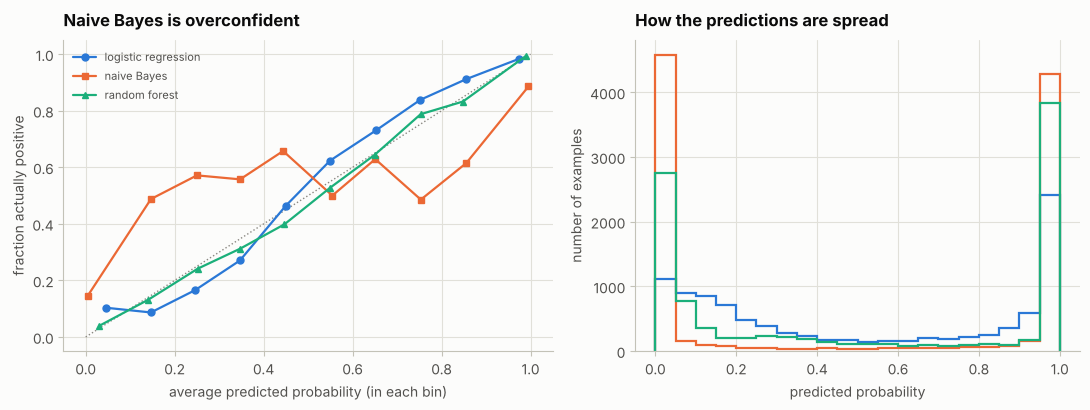

In [19]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.naive_bayes import GaussianNB

X_c, y_c = make_classification(n_samples=20_000, n_features=20, n_informative=2, n_redundant=10,
                               random_state=42)
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(X_c, y_c, test_size=0.5, random_state=0)

# make_classification builds a synthetic dataset; here 10 of the 20 features are mixtures of 2 informative ones
calibration_models = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "naive Bayes": GaussianNB(),
    "random forest": RandomForestClassifier(n_estimators=200, max_features=0.5, min_samples_leaf=5, n_jobs=-1, random_state=0),
}
calibration_probs = {name: m.fit(X_c_train, y_c_train).predict_proba(X_c_test)[:, 1]
                     for name, m in calibration_models.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
for (name, p), colour, marker in zip(calibration_probs.items(), PALETTE, ["o", "s", "^"]):
    frac_pos, mean_pred = calibration_curve(y_c_test, p, n_bins=10)
    axes[0].plot(mean_pred, frac_pos, color=colour, marker=marker, markersize=5, label=name)
    axes[1].hist(p, bins=20, range=(0, 1), histtype="step", color=colour, linewidth=1.6, label=name)
axes[0].set_xlabel("average predicted probability (in each bin)")
axes[0].set_ylabel("fraction actually positive")
axes[0].set_title("Naive Bayes is overconfident")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].set_xlabel("predicted probability")
axes[1].set_ylabel("number of examples")
axes[1].set_title("How the predictions are spread")
fig.tight_layout()
plt.show()

How to read it:

- **Logistic regression** lies close to the diagonal. This isn't luck: it's trained by minimising log loss, which rewards honest probabilities, so it's usually well calibrated when the model is a reasonable fit.
- **Naive Bayes** is far from the diagonal. When it says about 0.15, roughly half of those cases are positive; when it says about 0.85, only around 60% are. It's **overconfident**, and the histogram shows how: it pushes almost every prediction to the extremes near 0 and 1, leaving only a few hundred in between (which is also why its middle points jump around). The cause is its "naive" assumption that features are independent. Here half the features are mixtures of the same two informative ones, so it counts the same evidence many times over.
- **The random forest** is also close to the diagonal here. Forests often bend slightly away from 0 and 1, because a forest's probability is an average of many trees' votes and averaging pulls values towards the middle, but on this data the effect is small.

### Measuring calibration: Brier score and log loss

Two metrics score the probabilities directly, and both are **proper scoring rules**: they're best when the model reports its honest probability.

- The **Brier score** is the mean squared error between the probability and the outcome (0 or 1). Lower is better; predicting the base rate for everyone gives a baseline to beat.
- **Log loss** (cross-entropy, from Module 9) punishes confident wrong answers very heavily: predicting 0.99 for something that doesn't happen costs far more than predicting 0.7.

Both mix calibration and ranking together. To compare calibration alone, the reliability diagram is the clearest tool.

### Fixing calibration

`CalibratedClassifierCV` learns a mapping from the model's scores to calibrated probabilities, using cross-validation so the mapping is learned on data the model didn't train on. Two methods:

- **sigmoid** (Platt scaling): fits a logistic curve to the scores. Needs little data; works when the distortion is S-shaped.
- **isotonic**: fits any increasing step function. More flexible, but needs more data (roughly a thousand examples or more) or it overfits.

In [20]:
calibrated_nb = CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5).fit(X_c_train, y_c_train)
calibration_probs["naive Bayes, calibrated"] = calibrated_nb.predict_proba(X_c_test)[:, 1]

rows = {}
for name, p in calibration_probs.items():
    rows[name] = {"AUC": roc_auc_score(y_c_test, p), "Brier": brier_score_loss(y_c_test, p), "log loss": log_loss(y_c_test, p)}
rows["base rate for everyone"] = {"AUC": 0.5, "Brier": brier_score_loss(y_c_test, np.full(len(y_c_test), y_c_train.mean())),
                                  "log loss": log_loss(y_c_test, np.full(len(y_c_test), y_c_train.mean()))}
pd.DataFrame(rows).T.round(4)

,AUC,Brier,log loss
logistic regression,0.9299,0.0943,0.3302
naive Bayes,0.9224,0.1418,1.0014
random forest,0.9693,0.0607,0.2237
"naive Bayes, calibrated",0.9225,0.1111,0.3580
base rate for everyone,0.5000,0.2502,0.6936


Calibrating naive Bayes improves its Brier score and especially its log loss, which had been inflated by confident mistakes, while its AUC barely moves: the mapping is increasing, so it keeps the ranking (isotonic regression can merge some scores into ties, which shifts the AUC slightly). Calibration fixes what the probabilities **mean**, not how well the model **separates** the classes.

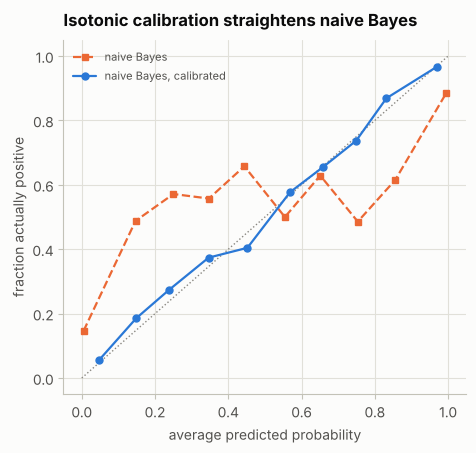

In [21]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
for name, colour, marker, style in [("naive Bayes", PALETTE[1], "s", "--"), ("naive Bayes, calibrated", PALETTE[0], "o", "-")]:
    frac_pos, mean_pred = calibration_curve(y_c_test, calibration_probs[name], n_bins=10)
    ax.plot(mean_pred, frac_pos, color=colour, marker=marker, markersize=5, linestyle=style, label=name)
ax.set_xlabel("average predicted probability")
ax.set_ylabel("fraction actually positive")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Isotonic calibration straightens naive Bayes")
plt.show()

Two rules for calibration in practice:

1. **Calibrate on data the model didn't train on.** A model's predictions on its own training data are overconfident, so calibrating on them makes things worse. `CalibratedClassifierCV` handles this with cross-validation.
2. **Calibration doesn't travel.** It's correct for data like the data it was checked on. If the base rate changes (a disease becomes more common, customers behave differently in a recession), probabilities that were calibrated become wrong even though the ranking may still be fine. The mini project shows a vivid example.

## 9. Class imbalance

Rare positives are normal: fraud, disease, machine failures, customers who buy. A common reaction is to "fix" the imbalance, by weighting the rare class more (`class_weight="balanced"`) or by resampling the training data (throwing away negatives, or duplicating or synthesising positives, as the popular SMOTE method does).

It's worth understanding what these actually do. Here's a dataset with 5% positives, and the same logistic regression trained normally and with class weights:

In [22]:
X_i, y_i = make_screening_data(20_000, prevalence=0.05, separation=2.0, seed=3)
X_i_train, X_i_test, y_i_train, y_i_test = train_test_split(X_i, y_i, test_size=0.5, stratify=y_i, random_state=0)

plain = LogisticRegression(max_iter=1000).fit(X_i_train, y_i_train)
weighted = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_i_train, y_i_train)
p_plain = plain.predict_proba(X_i_test)[:, 1]
p_weighted = weighted.predict_proba(X_i_test)[:, 1]

rows = {}
for name, p in [("plain", p_plain), ("class_weight='balanced'", p_weighted)]:
    pred = p >= 0.5
    rows[name] = {"AUC": roc_auc_score(y_i_test, p), "AP": average_precision_score(y_i_test, p),
                  "recall at 0.5": recall_score(y_i_test, pred), "precision at 0.5": precision_score(y_i_test, pred),
                  "average prediction": p.mean(), "Brier": brier_score_loss(y_i_test, p)}
print(f"actual positive rate: {y_i_test.mean():.3f}")
print("weights  plain:   ", plain.coef_.round(2), " intercept", plain.intercept_.round(2))
print("weights  weighted:", weighted.coef_.round(2), " intercept", weighted.intercept_.round(2))
pd.DataFrame(rows).T.round(3)

actual positive rate: 0.052
weights  plain:    [[0.9  0.83 0.88 0.89 0.81]]  intercept [-4.8]
weights  weighted: [[0.89 0.83 0.93 0.91 0.79]]  intercept [-1.91]


,AUC,AP,recall at 0.5,precision at 0.5,average prediction,Brier
plain,0.926,0.540,0.296,0.708,0.051,0.033
class_weight='balanced',0.926,0.539,0.866,0.231,0.259,0.114


Look at what changed and what didn't:

- **The ranking barely changed.** AUC and AP are almost identical. The weighted model isn't better at telling the classes apart.
- **At the default threshold of 0.5, the behaviour changed a lot.** The weighted model finds many more positives (higher recall) and is wrong more often when it flags one (lower precision).
- **The probabilities are now wrong.** The actual positive rate is 5%, but the weighted model's average prediction is far higher. Its Brier score is much worse.

In effect, class weighting mostly **moves the threshold**, and breaks the probabilities as a side effect. You can get nearly the same decisions from the plain model by lowering its threshold, and keep calibrated probabilities:

In [23]:
target_recall = recall_score(y_i_test, p_weighted >= 0.5)
for t in np.linspace(0.5, 0.01, 491):
    if recall_score(y_i_test, p_plain >= t) >= target_recall:
        break
print(f"weighted model at 0.5:    recall {recall_score(y_i_test, p_weighted >= 0.5):.3f}, precision {precision_score(y_i_test, p_weighted >= 0.5):.3f}")
print(f"plain model at {t:.3f}:    recall {recall_score(y_i_test, p_plain >= t):.3f}, precision {precision_score(y_i_test, p_plain >= t):.3f}")

weighted model at 0.5:    recall 0.866, precision 0.231
plain model at 0.051:    recall 0.868, precision 0.227


Very similar operating points. A medical study by van den Goorbergh and colleagues (2022) came to the same conclusion on real clinical data: imbalance corrections didn't improve how well models separated the classes, and they made the risk estimates worse.

So, practical advice:

- **Start with no correction.** Train normally, check calibration, and choose the threshold from costs or budget.
- **Class weights or resampling can help** when a model struggles to learn the rare class at all (for example, a tree model with few positives, or a neural network where positives are so rare that whole batches have none), or when training on all the negatives is too slow. If you use them, recalibrate the probabilities afterwards, or at least don't use them as probabilities.
- **Never resample the validation or test data.** They must look like the real world, or every metric you compute on them is wrong.
- **Imbalance is not the problem; few positives is.** 1,000 positives among 100,000 negatives is plenty to learn from. 20 positives is hard however you weight them, and the honest fix is more data.

## 10. More than two classes

With `k` classes, the confusion matrix is `k × k`: rows are actual classes, columns are predicted ones, and the diagonal holds the correct predictions. To make it interesting, here's a penguin species classifier that only gets to see two measurements, flipper length and body mass:

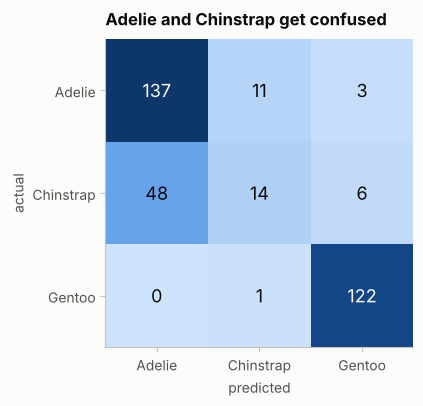

              precision    recall  f1-score   support

      Adelie      0.741     0.907     0.815       151
   Chinstrap      0.538     0.206     0.298        68
      Gentoo      0.931     0.992     0.961       123

    accuracy                          0.798       342
   macro avg      0.737     0.702     0.691       342
weighted avg      0.769     0.798     0.765       342



In [24]:
peng = penguins.dropna(subset=["flipper_length_mm", "body_mass_g"])
X_p = peng[["flipper_length_mm", "body_mass_g"]]
y_p = peng["species"]
pred_p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression()), X_p, y_p, cv=cv)
species = sorted(y_p.unique())

fig, ax = plt.subplots(figsize=(4.6, 4))
plot_confusion(confusion_matrix(y_p, pred_p, labels=species), species, ax, "Adelie and Chinstrap get confused")
plt.show()
print(classification_report(y_p, pred_p, digits=3))

Gentoo penguins are big and easy to recognise. Adelie and Chinstrap penguins have similar flippers and weights, so the model mixes them up, and since there are fewer Chinstraps, it mostly guesses Adelie.

Precision, recall and F1 are computed **per class**, treating each class in turn as positive and all the others as negative. To get one number, there are three ways to average:

- **Macro average**: the plain average over classes. Every class counts equally, however rare, so a model that fails on a small class is punished. Use it when every class matters.
- **Weighted average**: weighted by each class's support. Dominated by the big classes.
- **Micro average**: pool all the TP, FP and FN counts first, then compute the metric. For single-label problems, micro precision, micro recall and micro F1 all equal the **accuracy** (that's why the report just shows "accuracy").

Here Chinstrap's poor recall drags the macro average well below the accuracy. That gap is a useful warning sign: when macro and micro averages differ a lot, some class is being handled badly.

## 11. How sure are you? Comparing classifiers

A metric computed on a test set is an **estimate**. A different test set of the same size would give a different number. Before claiming that model A beats model B, ask whether the difference is bigger than this noise.

The **bootstrap** (Module 9) estimates the noise: resample the test cases with replacement many times, recompute the metric each time, and look at the spread. When comparing two models on the **same** test cases, resample the cases once and compute both models' metrics on that resample. This **paired** comparison is much more sensitive, because the two models' results go up and down together depending on which cases happen to be drawn.

Here's logistic regression against a k-nearest-neighbours classifier on the breast cancer data:

In [25]:
from sklearn.neighbors import KNeighborsClassifier

p_knn = cross_val_predict(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)), X_bc, y_bc,
                          cv=cv, method="predict_proba")[:, 1]
print(f"AUC  logistic {roc_auc_score(y_bc, p_bc):.4f}   k-NN {roc_auc_score(y_bc, p_knn):.4f}")

rng = np.random.default_rng(0)
y_arr = y_bc.to_numpy()
differences, auc_lr, auc_knn = [], [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():        # a resample with only one class has no AUC
        continue
    auc_lr.append(roc_auc_score(y_arr[idx], p_bc[idx]))
    auc_knn.append(roc_auc_score(y_arr[idx], p_knn[idx]))
    differences.append(auc_lr[-1] - auc_knn[-1])

for name, values in [("logistic AUC", auc_lr), ("k-NN AUC", auc_knn), ("difference", differences)]:
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"{name:<13} 95% interval {low:.4f} to {high:.4f}")
print(f"share of resamples where logistic regression wins: {np.mean(np.array(differences) > 0):.0%}")

AUC  logistic 0.9952   k-NN 0.9895


logistic AUC  95% interval 0.9896 to 0.9990
k-NN AUC      95% interval 0.9794 to 0.9972
difference    95% interval 0.0014 to 0.0119
share of resamples where logistic regression wins: 100%


The two models' individual intervals overlap a lot, which might suggest the difference is just noise. The paired interval for the **difference** is the right thing to look at, and here it doesn't include 0: logistic regression ranked better in every resample. On these tumours, its advantage is unlikely to be luck in which cases were drawn.

Two cautions about what the bootstrap can't tell you:

- It measures the noise from **which test cases you happened to have**. It doesn't include the noise from training (a different training set would give slightly different models), or any difference between your test data and the future.
- Here the predictions come from cross-validation, so they reuse the same 569 tumours for everything. For a final claim, use a test set that played no part in choosing the models.

And the most important caution of all: a difference can be **real but too small to matter**. An AUC of 0.995 against 0.990 rarely changes a single decision. Look at the metric that reflects the decisions (cost, precision at your budget) before declaring a winner.

## 12. A checklist for evaluating classifiers

1. **Know the base rate.** Report it next to every metric. Compare every model with the trivial baselines (always the majority class; random scores).
2. **Decide what the scores will be used for.** Ranking a list (AUC, precision at k), making yes/no decisions (costs, precision and recall at a threshold), or reporting risks (calibration).
3. **Evaluate on data the model never saw**, split the way the model will be used: future data for a model that predicts the future, new people for a model used on new people.
4. **Look at the confusion matrix** at the threshold you plan to use, not only a summary number.
5. **Choose the threshold deliberately**: from costs, from a budget, or from a required recall or precision. Choose it on validation data, never on the test set.
6. **Check calibration** if the probabilities will be used as probabilities, and recalibrate if needed.
7. **Leave the class balance alone** unless you have a specific reason; move the threshold instead.
8. **Report uncertainty**: a bootstrap interval, and paired comparisons between models.
9. **Break the results down** by group (region, age band, product). An average can hide a group the model handles badly.

## Summary

- **Accuracy** misleads when classes are imbalanced or mistakes have different costs. Always know the **base rate**.
- The **confusion matrix** (TP, FP, FN, TN) is the source of every metric. scikit-learn's layout is `[[TN, FP], [FN, TP]]`.
- **Recall**: what fraction of positives you find. **Precision**: what fraction of your positive predictions are right. **F1** combines them with a harmonic mean; **F-beta** weights one more. **Balanced accuracy** and **MCC** handle imbalance well.
- Classifiers produce **scores**; the **threshold** is a decision you make, and 0.5 is rarely right.
- **ROC/AUC** measures ranking across all thresholds and ignores the base rate; AUC is the chance a random positive outranks a random negative. **Precision-recall/AP** shows how many alerts are real and collapses when positives are rare; its baseline is the base rate.
- With costs, predict positive when **p > C_FP / (C_FP + C_FN)**, which needs **calibrated** probabilities. With a budget, rank and take the top k.
- **Calibration**: check with a reliability diagram, measure with the Brier score and log loss, fix with `CalibratedClassifierCV` (sigmoid or isotonic). It doesn't survive a change in base rate.
- **Class weighting and resampling** mostly move the threshold and break calibration; usually it's better to train normally and move the threshold.
- **Multiclass**: per-class metrics, then **macro** (every class equal), **weighted** or **micro** (equals accuracy) averages.
- Every metric is an estimate: use **paired bootstrap** intervals to compare models, and ask whether a difference is big enough to matter.

Next, open `02_exercises.ipynb`.